# Scientific Machine Learning with PyTorch

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/08_data/sciml_pytorch.ipynb)

[PyTorch Neural Networks](pytorch.ipynb) introduced tensors, automatic differentiation,
`torch.nn`, optimizers, and a classifier for handwritten digits.  This section uses the
same tools on problems from the rest of the course:

1. automatic differentiation as a numerical tool, compared with finite differences;
2. PyTorch's optimizers, compared with the methods of
   [Optimization Algorithms](../03_optimization/optimization_algorithms.ipynb);
3. fitting a function with a neural network, with mini-batches and a validation set;
4. fitting the parameters of an ODE by differentiating through the solver;
5. solving a boundary value problem with a physics-informed neural network.

At each step we compare with a classical method, because knowing when *not* to use a
neural network is as useful as knowing how to train one.

We work in double precision.  Deep learning normally uses single (or lower) precision for
speed, but here we want to see errors far below $10^{-7}$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd.functional import hessian
from scipy.optimize import minimize, rosen_hess
import scipy.sparse as sparse
import scipy.sparse.linalg as spla

torch.set_default_dtype(torch.float64)
torch.manual_seed(37830)
rng = np.random.default_rng(37830)

## Automatic differentiation is exact

Take $f(x) = \sin(3x)\, e^{-x^2}$ and compute $f'(0.7)$ three ways: by hand, by central
differences ([Differentiation](../04_functions/differentiation.ipynb)), and with autograd.

In [2]:
x0 = 0.7
exact = (3 * np.cos(3 * x0) - 2 * x0 * np.sin(3 * x0)) * np.exp(-x0**2)

x = torch.tensor(x0, requires_grad=True)
y = torch.sin(3 * x) * torch.exp(-x**2)
y.backward()
print(f"autograd error: {abs(x.grad.item() - exact):.1e}")

f_np = lambda x: np.sin(3 * x) * np.exp(-x**2)
for h in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]:
    fd = (f_np(x0 + h) - f_np(x0 - h)) / (2 * h)
    print(f"central difference, h = {h:.0e}: error {abs(fd - exact):.1e}")

autograd error: 0.0e+00
central difference, h = 1e-02: error 5.2e-04
central difference, h = 1e-04: error 5.2e-08
central difference, h = 1e-06: error 1.2e-10
central difference, h = 1e-08: error 3.0e-09
central difference, h = 1e-10: error 7.6e-07


Finite differences trade truncation error against round-off and never do better than
about $10^{-10}$ here.  Autograd has no step size: it applies the chain rule to the actual
sequence of operations that computed $y$, so the derivative is exact up to rounding.

PyTorch uses **reverse mode** automatic differentiation.  The forward computation records
a graph of operations, and `backward()` walks it from the output back to the inputs.  The
gradient of a scalar function of $n$ variables costs a small multiple of one function
evaluation, whatever $n$ is; a finite difference gradient costs $n + 1$ evaluations.  That
is why training networks with millions of parameters is feasible at all.

Second derivatives work the same way.  Here is the Hessian of the Rosenbrock function from
autograd, next to SciPy's hand-coded one:

In [3]:
def rosen_torch(z):
    """
    Rosenbrock function written with torch operations
    """
    return torch.sum(100 * (z[1:] - z[:-1]**2)**2 + (1 - z[:-1])**2)


z0 = torch.tensor([-1.2, 1.0])
print(hessian(rosen_torch, z0))
print(rosen_hess(z0.numpy()))

tensor([[1330.,  480.],
        [ 480.,  200.]])
[[1330.  480.]
 [ 480.  200.]]


A convenient pattern is to write the objective in PyTorch and hand value and gradient to
SciPy.  With `jac=True`, `minimize` expects the function to return both.

In [4]:
def value_and_grad(f_torch):
    """
    wrap a scalar torch function as a numpy function returning (value, gradient)
    """
    def wrapped(x):
        xt = torch.tensor(x, requires_grad=True)
        y = f_torch(xt)
        y.backward()
        return y.item(), xt.grad.numpy()
    return wrapped


res = minimize(value_and_grad(rosen_torch), np.zeros(10), jac=True, method='BFGS')
print(f"10-dimensional Rosenbrock: {res.nit} iterations, distance to the minimum "
      f"{np.linalg.norm(res.x - 1):.1e}")

10-dimensional Rosenbrock: 61 iterations, distance to the minimum 2.4e-08


## PyTorch optimizers

The optimizers in `torch.optim` are designed for training networks: millions of
parameters, gradients that are noisy because they come from mini-batches, and no need for
a very accurate minimum.  Most are variants of gradient descent with momentum.  `Adam`
also rescales each coordinate by a running estimate of the size of its gradient, which
makes it much less sensitive to badly scaled problems.

Here they are on the Rosenbrock function, a small deterministic problem, with the same
budget of 5000 gradient evaluations.  `LBFGS` re-evaluates the function inside its line
search, so it takes a `closure` that recomputes the loss.

In [5]:
results = {}
for name, make_opt in [("SGD", lambda p: torch.optim.SGD(p, lr=1e-3)),
                       ("SGD + momentum", lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9)),
                       ("Adam", lambda p: torch.optim.Adam(p, lr=1e-2))]:
    z = torch.tensor([-1.2, 1.0], requires_grad=True)
    opt = make_opt([z])
    for _ in range(5000):
        opt.zero_grad()
        loss = rosen_torch(z)
        loss.backward()
        opt.step()
    results[name] = (5000, z.detach())

z = torch.tensor([-1.2, 1.0], requires_grad=True)
opt = torch.optim.LBFGS([z], lr=1, max_iter=500, line_search_fn='strong_wolfe',
                        tolerance_grad=1e-12, tolerance_change=1e-15)


def closure():
    opt.zero_grad()
    loss = rosen_torch(z)
    loss.backward()
    return loss


opt.step(closure)
results["LBFGS"] = (opt.state[z]['func_evals'], z.detach())

for name, (evals, zf) in results.items():
    print(f"{name:15} {evals:5d} evaluations, distance to (1, 1): {torch.norm(zf - 1).item():.1e}")

SGD              5000 evaluations, distance to (1, 1): 1.3e-01
SGD + momentum   5000 evaluations, distance to (1, 1): 6.6e-10
Adam             5000 evaluations, distance to (1, 1): 4.9e-05
LBFGS              45 evaluations, distance to (1, 1): 6.7e-09


On a small smooth problem a quasi-Newton method wins easily, just as in
[Optimization Algorithms](../03_optimization/optimization_algorithms.ipynb): L-BFGS needs
a few dozen evaluations.  Plain SGD is still crawling along the valley after 5000 steps,
adding momentum makes a dramatic difference, and Adam's per-coordinate scaling buys little
on this problem.  Adam earns its place on large stochastic problems, where line searches
and curvature estimates are unreliable and the gradients of different parameters have very
different sizes.

## Fitting a function: mini-batches and validation

Now a regression problem: 200 noisy samples of $f(x) = \sin(3x)\, e^{-x^2/2}$ on
$[-3, 3]$, with noise of standard deviation $0.1$.  We hold back a quarter of the data as
a **validation set**, which is never used for training and tells us how well the model
does on data it has not seen.

In [6]:
f_true = lambda x: np.sin(3 * x) * np.exp(-x**2 / 2)

data_rng = np.random.default_rng(0)
x_data = data_rng.uniform(-3, 3, 200)
y_data = f_true(x_data) + 0.1 * data_rng.standard_normal(200)
order = data_rng.permutation(200)
train, val = order[:150], order[150:]

to_column = lambda a: torch.tensor(a).reshape(-1, 1)
X_train, Y_train = to_column(x_data[train]), to_column(y_data[train])
X_val, Y_val = to_column(x_data[val]), to_column(y_data[val])

A `DataLoader` serves the training data in shuffled **mini-batches**, so each optimizer
step uses a stochastic gradient, as in the SGD section of
[Optimization Algorithms](../03_optimization/optimization_algorithms.ipynb).  One pass
through the data is an **epoch**.  We train two networks: one plain, and one with **weight
decay**, which adds a penalty $\lambda \|\theta\|^2$ on the parameters.  That is the same
idea as ridge regression, applied to a network.

weight decay 0: 2.9 s, final training MSE 0.0078, final validation MSE 0.0176


weight decay 0.0001: 3.0 s, final training MSE 0.0088, final validation MSE 0.0134


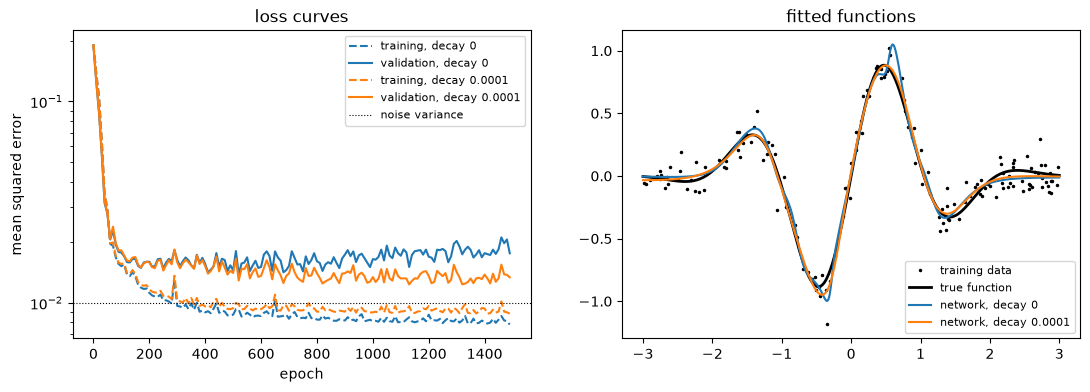

In [7]:
def make_mlp(width=64):
    return nn.Sequential(nn.Linear(1, width), nn.Tanh(),
                         nn.Linear(width, width), nn.Tanh(),
                         nn.Linear(width, 1))


def train_mlp(weight_decay, epochs=1500, batch_size=50, lr=3e-3, seed=0):
    """
    train an MLP on (X_train, Y_train); return the model and a loss history
    """
    torch.manual_seed(seed)
    model = make_mlp()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
    mse = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = mse(model(xb), yb)
            loss.backward()
            opt.step()
        if epoch % 10 == 0:
            with torch.no_grad():
                history.append((epoch, mse(model(X_train), Y_train).item(),
                                mse(model(X_val), Y_val).item()))
    return model, np.array(history)


models = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for wd, color in [(0.0, 'C0'), (1e-4, 'C1')]:
    start = time.perf_counter()
    model, hist = train_mlp(wd)
    models[wd] = model
    print(f"weight decay {wd:g}: {time.perf_counter() - start:.1f} s, final training MSE "
          f"{hist[-1, 1]:.4f}, final validation MSE {hist[-1, 2]:.4f}")
    ax[0].semilogy(hist[:, 0], hist[:, 1], color=color, ls='--', label=f'training, decay {wd:g}')
    ax[0].semilogy(hist[:, 0], hist[:, 2], color=color, label=f'validation, decay {wd:g}')
ax[0].axhline(0.01, color='k', lw=0.8, ls=':', label='noise variance')
ax[0].set_xlabel('epoch')
ax[0].set_ylabel('mean squared error')
ax[0].legend(fontsize=8)
ax[0].set_title('loss curves')

xs = np.linspace(-3, 3, 400)
ax[1].plot(x_data[train], y_data[train], 'k.', ms=3, label='training data')
ax[1].plot(xs, f_true(xs), 'k', lw=2, label='true function')
with torch.no_grad():
    for wd, color in [(0.0, 'C0'), (1e-4, 'C1')]:
        ax[1].plot(xs, models[wd](to_column(xs)).numpy(), color=color, label=f'network, decay {wd:g}')
ax[1].legend(fontsize=8)
ax[1].set_title('fitted functions')
plt.show()

The training error of the plain network falls *below* the noise variance $0.01$: it is
starting to fit the noise, and the validation error creeps up as it does.  This is
**overfitting**.  The usual remedies are to stop training when the validation error is
lowest (**early stopping**) or to regularize, as with weight decay here.  None of these
choices can be made without held-out data.

For comparison, here is a classical fit: a least squares Chebyshev polynomial, with the
degree chosen by the same validation set (compare [Interpolation](../04_functions/interpolation.ipynb)).

In [8]:
from numpy.polynomial import Chebyshev

val_mse = {}
for deg in range(5, 26):
    p = Chebyshev.fit(x_data[train], y_data[train], deg)
    val_mse[deg] = np.mean((p(x_data[val]) - y_data[val])**2)
best = min(val_mse, key=val_mse.get)
start = time.perf_counter()
p = Chebyshev.fit(x_data[train], y_data[train], best)
print(f"best degree {best}: validation MSE {val_mse[best]:.4f}, "
      f"fit in {1e3 * (time.perf_counter() - start):.1f} ms")

best degree 20: validation MSE 0.0130, fit in 0.2 ms


A single least squares solve does as well as a few seconds of training.  For a smooth
function of one variable this is typical, and classical approximation is hard to beat.
Networks earn their keep when the input has many dimensions or complicated structure
(images, molecules, text), where polynomial bases and grids are hopeless.

## Differentiating through a simulation

Because autograd differentiates any sequence of tensor operations, it can differentiate
through a whole simulation.  Take a damped oscillator

$$ x'' + 2\zeta\omega\, x' + \omega^2 x = 0, \qquad x(0) = 1,\ x'(0) = 0, $$

observed at 41 times with noise, and fit the frequency $\omega$ and damping ratio $\zeta$.
We write RK4 ([ODE Solvers](../05_differential_equations/ode_solvers.ipynb)) with torch
operations, so the loss is a differentiable function of the parameters.

In [9]:
def rk4_torch(rhs, y0, dt, nsteps):
    """
    fixed-step RK4 written in torch so that autograd can differentiate through it
    """
    y, ys = y0, [y0]
    for _ in range(nsteps):
        k1 = rhs(y)
        k2 = rhs(y + dt / 2 * k1)
        k3 = rhs(y + dt / 2 * k2)
        k4 = rhs(y + dt * k3)
        y = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        ys.append(y)
    return torch.stack(ys)


T, nsteps = 10.0, 200
t_grid = torch.linspace(0, T, nsteps + 1)
obs = torch.arange(0, nsteps + 1, 5)              # observe every 5th step


def oscillator(omega, zeta):
    rhs = lambda y: torch.stack([y[1], -2 * zeta * omega * y[1] - omega**2 * y[0]])
    return rk4_torch(rhs, torch.tensor([1.0, 0.0]), T / nsteps, nsteps)[:, 0]


with torch.no_grad():
    x_clean = oscillator(torch.tensor(2.0), torch.tensor(0.1))
measured = x_clean[obs] + 0.05 * torch.tensor(rng.standard_normal(len(obs)))

We optimize the logarithms of the parameters, which keeps them positive, starting from a
poor guess.

0.8 s, 12 simulations
omega = 2.0038 (true 2.0), zeta = 0.1011 (true 0.1)


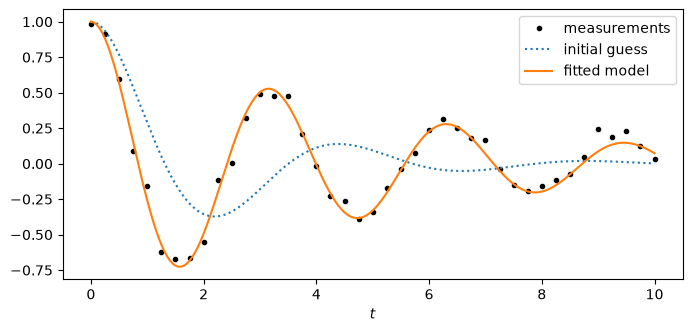

In [10]:
log_omega = torch.tensor(np.log(1.5), requires_grad=True)
log_zeta = torch.tensor(np.log(0.3), requires_grad=True)
opt = torch.optim.LBFGS([log_omega, log_zeta], lr=1, max_iter=100, line_search_fn='strong_wolfe')


def closure():
    opt.zero_grad()
    loss = torch.mean((oscillator(log_omega.exp(), log_zeta.exp())[obs] - measured)**2)
    loss.backward()
    return loss


start = time.perf_counter()
opt.step(closure)
print(f"{time.perf_counter() - start:.1f} s, {opt.state[log_omega]['func_evals']} simulations")
print(f"omega = {log_omega.exp().item():.4f} (true 2.0), zeta = {log_zeta.exp().item():.4f} (true 0.1)")

with torch.no_grad():
    fitted = oscillator(log_omega.exp(), log_zeta.exp())
    guess = oscillator(torch.tensor(1.5), torch.tensor(0.3))
plt.figure(figsize=(8, 3.5))
plt.plot(t_grid[obs], measured, 'k.', label='measurements')
plt.plot(t_grid, guess, ':', label='initial guess')
plt.plot(t_grid, fitted, label='fitted model')
plt.xlabel('$t$')
plt.legend()
plt.show()

Each gradient cost one forward simulation plus one backward pass through the recorded
operations, and that cost does not depend on the number of parameters.  A finite
difference gradient would need an extra simulation per parameter.  For models with
thousands of parameters (a spatially varying coefficient in a PDE, the weights of a
network inside an ODE) this difference is decisive.  It is the idea behind **adjoint
methods** in PDE-constrained optimization and behind **neural ODEs**.

Two caveats.  Backpropagation stores every intermediate value of the simulation, so memory
grows with the number of time steps.  And autograd differentiates the *discretized*
problem, so the gradient is only as meaningful as the solver is accurate.

## Physics-informed neural networks

A **physics-informed neural network (PINN)** represents the solution of a differential
equation as a network $u_\theta(x)$ and trains it to satisfy the equation.  For the
boundary value problem ([Boundary Value Problems](../05_differential_equations/bvp.ipynb))

$$ -u''(x) = \pi^2 \sin(\pi x), \qquad u(0) = u(1) = 0, $$

whose solution is $u = \sin(\pi x)$, the loss is the mean squared residual of the equation
at a set of **collocation points**, plus a penalty on the boundary values.  The derivatives
$u_\theta''$ with respect to the *input* $x$ also come from autograd; `create_graph=True`
keeps the graph so that the loss can itself be differentiated with respect to the weights.

after 3000 Adam steps: max error 1.6e-04


after L-BFGS refinement: max error 7.9e-07, total training time 3.1 s


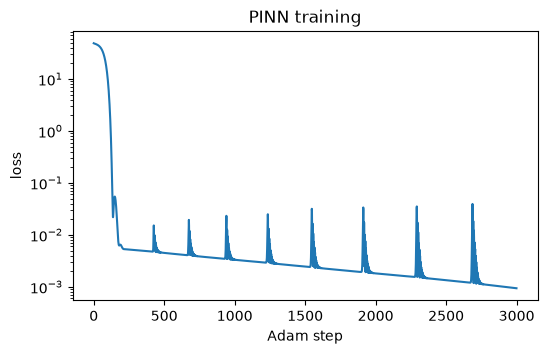

In [11]:
torch.manual_seed(0)
pinn = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))

x_col = torch.linspace(0, 1, 64)[1:-1].reshape(-1, 1).requires_grad_(True)
x_bc = torch.tensor([[0.0], [1.0]])
source = lambda x: np.pi**2 * torch.sin(np.pi * x)


def pinn_loss():
    u = pinn(x_col)
    du = torch.autograd.grad(u.sum(), x_col, create_graph=True)[0]
    d2u = torch.autograd.grad(du.sum(), x_col, create_graph=True)[0]
    residual = -d2u - source(x_col)
    return torch.mean(residual**2) + 100 * torch.mean(pinn(x_bc)**2)


x_test = torch.linspace(0, 1, 201).reshape(-1, 1)
pinn_error = lambda: (pinn(x_test) - torch.sin(np.pi * x_test)).abs().max().item()

start = time.perf_counter()
adam = torch.optim.Adam(pinn.parameters(), lr=1e-3)
losses = []
for _ in range(3000):
    adam.zero_grad()
    loss = pinn_loss()
    loss.backward()
    adam.step()
    losses.append(loss.item())
with torch.no_grad():
    print(f"after 3000 Adam steps: max error {pinn_error():.1e}")

lbfgs = torch.optim.LBFGS(pinn.parameters(), lr=1, max_iter=500, line_search_fn='strong_wolfe',
                          tolerance_grad=1e-12, tolerance_change=1e-15)


def closure():
    lbfgs.zero_grad()
    loss = pinn_loss()
    loss.backward()
    return loss


lbfgs.step(closure)
with torch.no_grad():
    print(f"after L-BFGS refinement: max error {pinn_error():.1e}, "
          f"total training time {time.perf_counter() - start:.1f} s")

plt.figure(figsize=(6, 3.5))
plt.semilogy(losses)
plt.xlabel('Adam step')
plt.ylabel('loss')
plt.title('PINN training')
plt.show()

Now the same problem with the second-order finite difference method: one sparse
tridiagonal solve.

In [12]:
for n in [16, 64, 256]:
    h = 1 / (n + 1)
    x = np.linspace(h, 1 - h, n)
    A = sparse.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n), format='csc') / h**2
    start = time.perf_counter()
    u = spla.spsolve(A, np.pi**2 * np.sin(np.pi * x))
    elapsed = time.perf_counter() - start
    print(f"finite differences, n = {n:3d}: max error {np.max(np.abs(u - np.sin(np.pi * x))):.1e}, "
          f"{1e3 * elapsed:.2f} ms")

finite differences, n =  16: max error 2.8e-03, 0.13 ms
finite differences, n =  64: max error 1.9e-04, 0.13 ms
finite differences, n = 256: max error 1.2e-05, 0.10 ms


The PINN ends up more accurate than finite differences on 256 points, but it took seconds
of training against a fraction of a millisecond.  Since the finite difference error falls
like $h^2$, about a thousand points would match the PINN, still in about a millisecond, and
a spectral method ([Spectral Methods](../05_differential_equations/spectral_methods.ipynb))
would reach machine precision with a few dozen points.  The training is also a non-convex optimization
problem with no guarantee of success, and the result depends on the network, the
collocation points, the penalty weight, and the random initialization.

For forward problems like this one, in low dimensions, classical methods are faster, more
accurate, and come with error estimates.  PINNs and related methods are worth considering
when those methods are awkward: inverse problems with scattered measurements, where the
data and the equation are combined in one loss; problems in many dimensions, where grids
are impossible; or when you need a differentiable surrogate for a whole family of
problems.

## Exercises

### Exercise 1

Compute the Jacobian of the Robertson right-hand side from
[ODE Solvers](../05_differential_equations/ode_solvers.ipynb) with
`torch.autograd.functional.jacobian`, wrap it as a function `jac(t, y)` returning a NumPy
array, and pass it to `solve_ivp(..., method='BDF', jac=jac)`.  Check it against the
Jacobian derived by hand.  Does it change the number of steps or function evaluations?

In [13]:
# Your code here

### Exercise 2

Implement early stopping in `train_mlp`: keep a copy of the parameters (`copy.deepcopy`
of `model.state_dict()`) whenever the validation error reaches a new minimum, and restore
the best copy at the end.  Compare the validation error with that of weight decay.  Why
is it a mistake to report the validation error of the selected model as an estimate of its
error on new data?

In [14]:
# Your code here

### Exercise 3

Use `rk4_torch` and `LBFGS` to recover the three rates $\alpha, \beta, \gamma$ of the
lion-zebra model from the noisy counts in
[Optimization Algorithms](../03_optimization/optimization_algorithms.ipynb).  Compare the
estimates and the run time with `least_squares`.

In [15]:
# Your code here

### Exercise 4

Turn the PINN into an inverse problem.  Suppose the equation is $-k\, u'' = \pi^2 \sin(\pi x)$
with an unknown constant $k > 0$, and you have noisy measurements of $u$ at 10 points
generated with $k = 2$.  Make $\log k$ a trainable parameter, add a data misfit term to the
loss, and train.  How well is $k$ recovered as the noise level grows?

In [16]:
# Your code here

### Exercise 5

If you have access to a GPU (Google Colab provides one), time a single training step of
`make_mlp(width)` on a batch of 4096 points, on the CPU and on the GPU, for widths 64, 512,
and 4096.  Remember to move both the model and the data with `.to('cuda')`, and to call
`torch.cuda.synchronize()` before stopping the timer.  At what size does the GPU start to
pay off?

In [17]:
# Your code here